# 08 — Regularization Experiments: Lasso, Ridge & Elastic Net (Classification & Regression)

## 1. Imports and Configuration


In [1]:
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, brier_score_loss
)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['figure.dpi'] = 150
plt.rcParams['axes.titlesize'] = 12

RANDOM_STATE = 42

DATA_PATH = os.path.join('..', '..', 'data', 'processed', 'loan_featured.xlsx')
if not os.path.exists(DATA_PATH):
    DATA_PATH = os.path.join('data', 'processed', 'loan_featured.xlsx')

print(f'Loading data from: {DATA_PATH}')

Loading data from: ..\..\data\processed\loan_featured.xlsx


## 2. Ingestion & Preprocessing Setup


In [2]:
df = pd.read_excel(DATA_PATH, sheet_name='Loan_Featured')

# Binary target
y = (df['Loan_Default'] == 'Yes').astype(int)

# Exclude leakage
drop_cols = ['Applicant_ID', 'Application_Date', 'Risk_Category', 'Loan_Default']
X = df.drop(columns=drop_cols)

# Stratified 80/20 train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

numeric_cols = [
    'Age', 'Years_Employed', 'Annual_Income', 'Loan_Amount', 'Loan_Term_Months',
    'Interest_Rate_Pct', 'Credit_Score', 'Credit_History_Years', 'Existing_Loans',
    'Total_Credit_Limit', 'Credit_Utilization_Pct', 'Late_Payments_2Y',
    'Monthly_Debt_Payment', 'Savings_Balance', 'Checking_Balance',
    'Debt_to_Income', 'Loan_to_Income', 'Loan_to_Value', 'Savings_to_Income',
    'Log_Annual_Income', 'Log_Loan_Amount', 'Log_Savings_Balance'
]

nominal_cols = [
    'Marital_Status', 'Home_Ownership', 'Employment_Type', 'Employer_Sector',
    'Loan_Purpose', 'Region', 'Application_Channel'
]

binary_cols = [
    'Gender', 'Salary_Account_With_Bank', 'Vehicle_Owned', 'Has_Co_Applicant',
    'Previous_Default', 'Mobile_Banking_User', 'Ever_Delinquent', 'Is_Home_Loan'
]

ordinal_cols = ['Education_Level']
education_hierarchy = [['High School', 'Diploma', 'Bachelor', 'Master', 'PhD']]

# Preprocessor: Scaling is mandatory for regularized logistic regression!
preprocessor = ColumnTransformer(transformers=[
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), numeric_cols),
    ('nom', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('ohe', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'))]), nominal_cols),
    ('ord', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('ord', OrdinalEncoder(categories=education_hierarchy))]), ordinal_cols),
    ('bin', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('enc', OrdinalEncoder())]), binary_cols)
], remainder='drop')


## 3. Fitting L1, L2 and Elastic Net across C Values


In [3]:
# Transform training and test matrices
X_train_trans = preprocessor.fit_transform(X_train)
X_test_trans = preprocessor.transform(X_test)

c_values = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]
results_list = []
coef_l1_history = []
coef_l2_history = []

for c in c_values:
    # 1. L1 (Lasso) using saga solver
    lr_l1 = LogisticRegression(penalty='l1', C=c, solver='saga', max_iter=2000, random_state=RANDOM_STATE)
    lr_l1.fit(X_train_trans, y_train)
    y_prob_l1 = lr_l1.predict_proba(X_test_trans)[:, 1]
    y_pred_l1 = lr_l1.predict(X_test_trans)
    
    n_zeros_l1 = np.sum(lr_l1.coef_[0] == 0.0)
    n_active_l1 = np.sum(lr_l1.coef_[0] != 0.0)
    coef_l1_history.append(lr_l1.coef_[0])
    
    results_list.append({
        'Penalty': 'L1 (Lasso)',
        'C': c,
        'Zero_Coefficients': n_zeros_l1,
        'Active_Features': n_active_l1,
        'Test_Accuracy': accuracy_score(y_test, y_pred_l1),
        'Test_Recall': recall_score(y_test, y_pred_l1),
        'Test_F1': f1_score(y_test, y_pred_l1),
        'Test_ROC_AUC': roc_auc_score(y_test, y_prob_l1)
    })
    
    # 2. L2 (Ridge) using lbfgs solver
    lr_l2 = LogisticRegression(penalty='l2', C=c, solver='lbfgs', max_iter=2000, random_state=RANDOM_STATE)
    lr_l2.fit(X_train_trans, y_train)
    y_prob_l2 = lr_l2.predict_proba(X_test_trans)[:, 1]
    y_pred_l2 = lr_l2.predict(X_test_trans)
    
    n_zeros_l2 = np.sum(lr_l2.coef_[0] == 0.0)
    n_active_l2 = np.sum(lr_l2.coef_[0] != 0.0)
    coef_l2_history.append(lr_l2.coef_[0])
    
    results_list.append({
        'Penalty': 'L2 (Ridge)',
        'C': c,
        'Zero_Coefficients': n_zeros_l2,
        'Active_Features': n_active_l2,
        'Test_Accuracy': accuracy_score(y_test, y_pred_l2),
        'Test_Recall': recall_score(y_test, y_pred_l2),
        'Test_F1': f1_score(y_test, y_pred_l2),
        'Test_ROC_AUC': roc_auc_score(y_test, y_prob_l2)
    })

df_reg_results = pd.DataFrame(results_list)
df_reg_results.to_csv('../../outputs/tables/lasso_ridge_c_experiment.csv', index=False)

print('=== Regularization Experiment Results across C values ===')
display(df_reg_results)

=== Regularization Experiment Results across C values ===


,Penalty,C,Zero_Coefficients,Active_Features,Test_Accuracy,Test_Recall,Test_F1,Test_ROC_AUC
0,L1 (Lasso),0.001,56,1,0.8020,0.000000,0.000000,0.810530
1,L2 (Ridge),0.001,0,57,0.8400,0.265152,0.396226,0.864901
2,L1 (Lasso),0.010,46,11,0.8445,0.361111,0.479062,0.864845
3,L2 (Ridge),0.010,0,57,0.8530,0.424242,0.533333,0.881978
4,L1 (Lasso),0.100,28,29,0.8650,0.502525,0.595808,0.888152
5,L2 (Ridge),0.100,0,57,0.8640,0.510101,0.597633,0.889185
6,L1 (Lasso),1.000,2,55,0.8665,0.522727,0.607930,0.890240
7,L2 (Ridge),1.000,0,57,0.8650,0.520202,0.604106,0.890460
8,L1 (Lasso),10.000,0,57,0.8645,0.520202,0.603221,0.890662
9,L2 (Ridge),10.000,0,57,0.8640,0.517677,0.601173,0.890583


## 4. Visualising Sparsity & Regularization Paths


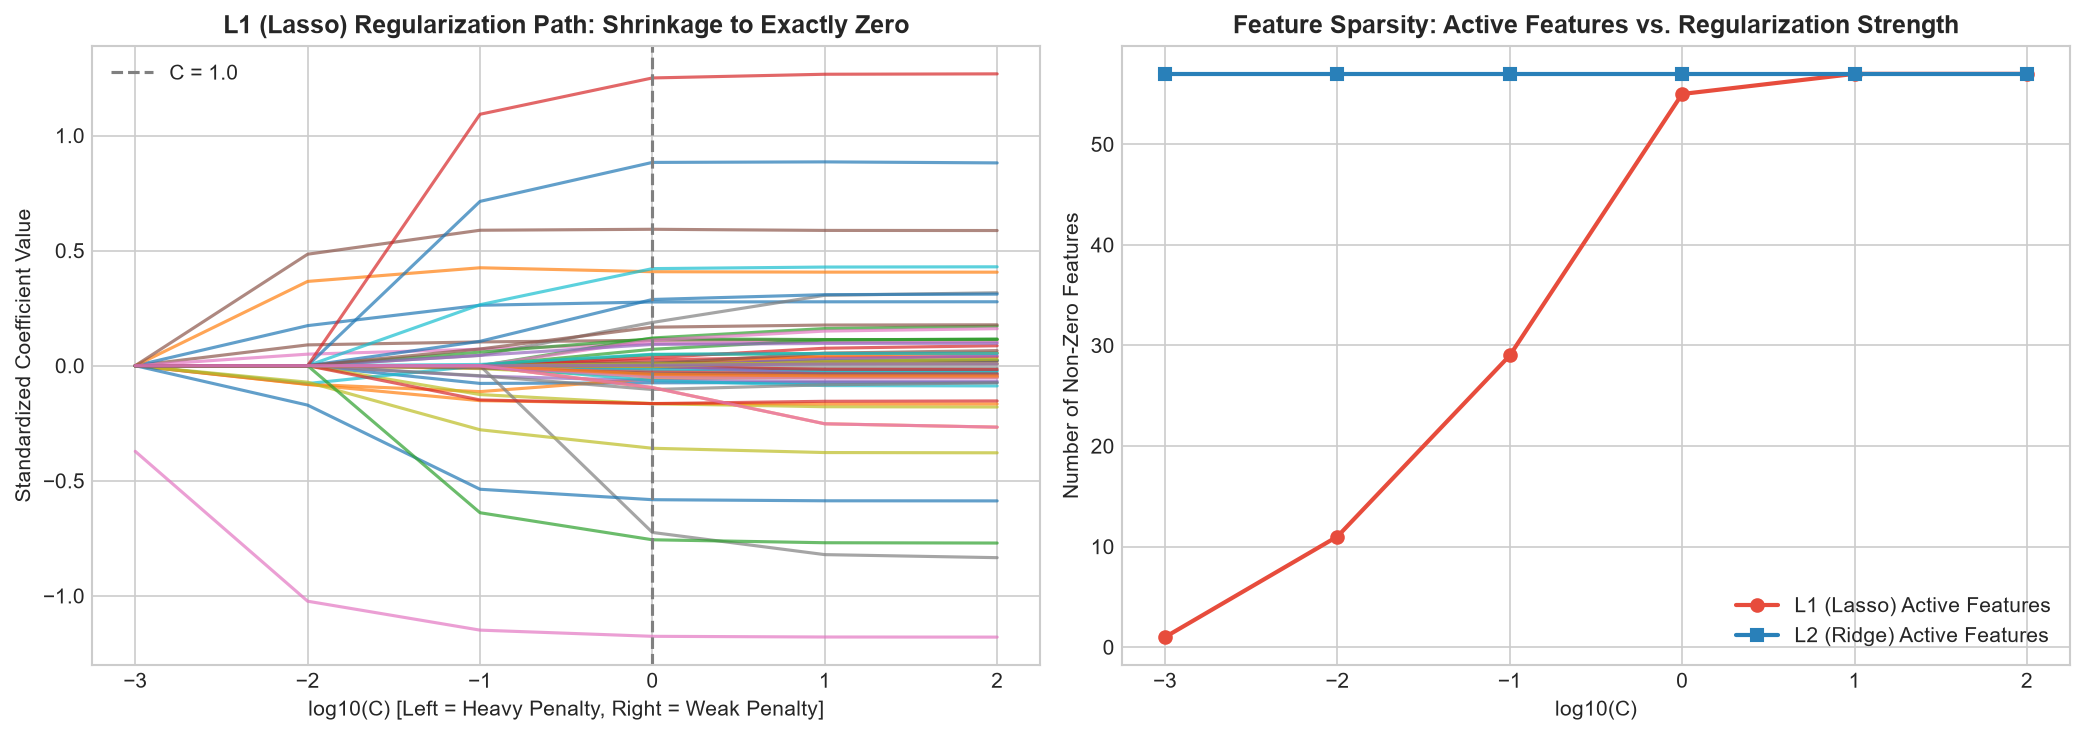

In [4]:
# Extract feature names
feature_names = (
    numeric_cols +
    list(preprocessor.named_transformers_['nom'].named_steps['ohe'].get_feature_names_out(nominal_cols)) +
    ordinal_cols +
    binary_cols
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot L1 coefficient paths
coef_l1_matrix = np.array(coef_l1_history)
for j in range(len(feature_names)):
    axes[0].plot(np.log10(c_values), coef_l1_matrix[:, j], alpha=0.7)
axes[0].set_title('L1 (Lasso) Regularization Path: Shrinkage to Exactly Zero', weight='bold')
axes[0].set_xlabel('log10(C) [Left = Heavy Penalty, Right = Weak Penalty]')
axes[0].set_ylabel('Standardized Coefficient Value')
axes[0].axvline(0, color='gray', linestyle='--', label='C = 1.0')
axes[0].legend()

# Plot Active Features vs C
l1_df = df_reg_results[df_reg_results['Penalty'] == 'L1 (Lasso)']
l2_df = df_reg_results[df_reg_results['Penalty'] == 'L2 (Ridge)']

axes[1].plot(np.log10(l1_df['C']), l1_df['Active_Features'], marker='o', color='#e74c3c', lw=2, label='L1 (Lasso) Active Features')
axes[1].plot(np.log10(l2_df['C']), l2_df['Active_Features'], marker='s', color='#2980b9', lw=2, label='L2 (Ridge) Active Features')
axes[1].set_title('Feature Sparsity: Active Features vs. Regularization Strength', weight='bold')
axes[1].set_xlabel('log10(C)')
axes[1].set_ylabel('Number of Non-Zero Features')
axes[1].legend()

plt.tight_layout()
plt.savefig('../../outputs/figures/loan_default_regularization_paths.png', dpi=150)
plt.show()

**Takeaway:** L1 (Lasso) regularization forces irrelevant coefficients to exactly zero as penalty strength increases, providing automated feature selection while preserving the core risk drivers.

## 5. Sparse Feature Selection: The Core Credit Risk Signal


In [5]:
# Inspect the model coefficients at C=0.01 (Sparse model)
sparse_lr = LogisticRegression(penalty='l1', C=0.01, solver='saga', max_iter=2000, random_state=RANDOM_STATE)
sparse_lr.fit(X_train_trans, y_train)

df_sparse_coef = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient_at_C_0_01': sparse_lr.coef_[0]
}).query('Coefficient_at_C_0_01 != 0.0').sort_values('Coefficient_at_C_0_01', key=abs, ascending=False).reset_index(drop=True)

print('=== Top Surviving Features Selected by Lasso at Heavy Penalty (C=0.01) ===')
display(df_sparse_coef)

=== Top Surviving Features Selected by Lasso at Heavy Penalty (C=0.01) ===


,Feature,Coefficient_at_C_0_01
0,Credit_Score,-1.023370
1,Debt_to_Income,0.484366
2,Late_Payments_2Y,0.366139
3,Credit_Utilization_Pct,0.173977
4,Salary_Account_With_Bank,-0.171399
5,Interest_Rate_Pct,0.090339
6,Log_Savings_Balance,-0.081683
7,Years_Employed,-0.080844
8,Log_Annual_Income,-0.077670
9,Employment_Type_Salaried,-0.071730


## 6. Continuous Lending Regression Benchmark: Risk-Based Interest Rate Pricing

### 6.1 Purpose in the Banking Context: Actuarial Risk-Based Pricing
In retail and commercial credit operations, underwriting comprises two distinct decision stages:
1. **Underwriting Decision (Classification):** Determining whether to approve or decline the loan applicant based on default probability ($P(\text{Default})$).
2. **Risk-Based Pricing (Continuous Regression):** Determining the appropriate contractual interest rate ($\text{Interest\_Rate\_Pct}$) to assign to approved borrowers.

Under the actuarial risk-based pricing framework, a bank cannot charge a uniform interest rate across all borrowers. The contractual interest rate is structured to cover:
$$\text{Contractual Interest Rate} = \text{Base Cost of Funds} + \text{Operating Expenses} + \text{Expected Loss (PD} \times \text{LGD} \times \text{EAD)} + \text{Target Capital Hurdle}$$

Borrowers presenting elevated risk profiles (lower credit scores, high debt-to-income ratios, history of delinquency, unsecured loan purposes) must be quoted higher interest rates to compensate the lending institution for higher anticipated credit losses.

### 6.2 Comparison of Regression Estimators
To establish an optimal risk-based pricing benchmark on the continuous target `Interest_Rate_Pct`, we implement, cross-validate, and evaluate the three foundational linear regression paradigms:
* **Ordinary Least Squares (OLS):** The classical unpenalized linear regression estimator minimizing the Residual Sum of Squares ($\text{RSS}$). Provides Best Linear Unbiased Estimates (BLUE) under Gauss-Markov assumptions, but is susceptible to severe variance inflation when credit predictors are multicollinear (e.g., strong correlations between loan amount, property value, and income).
* **Ridge Regression ($L_2$ Regularization):** Minimizes $\text{RSS} + \lambda \sum_{j=1}^{p} \beta_j^2$. By penalizing the squared $L_2$ norm of the weight vector, Ridge continuously shrinks coefficients toward zero. This stabilizes matrix conditioning, dampens coefficient variance, and mitigates multicollinearity without removing any feature.
* **Lasso Regression ($L_1$ Regularization):** Minimizes $\text{RSS} + \lambda \sum_{j=1}^{p} |\beta_j|$. By applying a non-differentiable penalty at zero, Lasso drives non-essential or redundant coefficients to exactly zero, performing automated variable selection to produce a parsimonious, highly auditable pricing model.


In [6]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_val_score

# 1. Regression Target & Feature Matrix Setup
# Valid continuous target from actual dataset: Interest_Rate_Pct
y_reg = df['Interest_Rate_Pct']

# Exclude target, classification outcomes, and non-predictive identifiers/metadata
drop_cols_reg = ['Interest_Rate_Pct', 'Loan_Default', 'Risk_Category', 'Applicant_ID', 'Application_Date']
X_reg = df.drop(columns=drop_cols_reg)

# 80/20 Train-Test Partition (matching project standard)
X_tr_reg, X_te_reg, y_tr_reg, y_te_reg = train_test_split(
    X_reg, y_reg, test_size=0.20, random_state=RANDOM_STATE
)

# Build preprocessor specifically for regression features (excluding Interest_Rate_Pct from numeric predictors)
numeric_cols_reg = [c for c in numeric_cols if c != 'Interest_Rate_Pct']

reg_preprocessor = ColumnTransformer(transformers=[
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), numeric_cols_reg),
    ('nom', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('ohe', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'))]), nominal_cols),
    ('ord', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('ord', OrdinalEncoder(categories=education_hierarchy))]), ordinal_cols),
    ('bin', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('enc', OrdinalEncoder())]), binary_cols)
], remainder='drop')

# Fit preprocessor on training partition only to prevent data leakage
X_tr_reg_trans = reg_preprocessor.fit_transform(X_tr_reg)
X_te_reg_trans = reg_preprocessor.transform(X_te_reg)

n_train, p_features = X_tr_reg_trans.shape
n_test = X_te_reg_trans.shape[0]

# Extract transformed feature names
nom_features = list(reg_preprocessor.named_transformers_['nom'].named_steps['ohe'].get_feature_names_out(nominal_cols))
reg_feature_names = numeric_cols_reg + nom_features + ordinal_cols + binary_cols

# 2. Instantiate Benchmark Models
reg_models = {
    'OLS (Linear Regression)': LinearRegression(),
    'Ridge Regression (L2)': Ridge(alpha=10.0, random_state=RANDOM_STATE),
    'Lasso Regression (L1)': Lasso(alpha=0.05, max_iter=2000, random_state=RANDOM_STATE)
}

kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

reg_results = []
fitted_reg = {}
reg_predictions = {}
reg_residuals = {}

for name, model in reg_models.items():
    # 5-Fold Cross-Validation on training data
    cv_scores = cross_val_score(model, X_tr_reg_trans, y_tr_reg, cv=kf, scoring='r2', n_jobs=-1)
    
    # Fit model on training split
    model.fit(X_tr_reg_trans, y_tr_reg)
    fitted_reg[name] = model
    
    # Train set predictions & metrics
    y_tr_pred = model.predict(X_tr_reg_trans)
    tr_r2 = r2_score(y_tr_reg, y_tr_pred)
    tr_mae = mean_absolute_error(y_tr_reg, y_tr_pred)
    tr_mse = mean_squared_error(y_tr_reg, y_tr_pred)
    tr_rmse = np.sqrt(tr_mse)
    
    # Test set predictions & metrics
    y_te_pred = model.predict(X_te_reg_trans)
    reg_predictions[name] = y_te_pred
    reg_residuals[name] = y_te_reg - y_te_pred
    
    te_r2 = r2_score(y_te_reg, y_te_pred)
    te_adj_r2 = 1.0 - (1.0 - te_r2) * (n_test - 1) / (n_test - p_features - 1)
    te_mae = mean_absolute_error(y_te_reg, y_te_pred)
    te_mse = mean_squared_error(y_te_reg, y_te_pred)
    te_rmse = np.sqrt(te_mse)
    
    gap = tr_r2 - te_r2
    fit_status = 'Good Fit' if gap < 0.03 else ('Overfitting' if gap > 0.08 else 'Moderate Fit')
    
    reg_results.append({
        'Model': name,
        'Train_R2': round(tr_r2, 4),
        'Test_R2': round(te_r2, 4),
        'Test_Adj_R2': round(te_adj_r2, 4),
        'CV_R2_Mean': round(cv_scores.mean(), 4),
        'CV_R2_Std': round(cv_scores.std(), 4),
        'Train_MAE': round(tr_mae, 4),
        'Test_MAE': round(te_mae, 4),
        'Train_RMSE': round(tr_rmse, 4),
        'Test_RMSE': round(te_rmse, 4),
        'Generalization_Gap': round(gap, 4),
        'Fit_Status': fit_status
    })

df_reg_benchmark = pd.DataFrame(reg_results)
os.makedirs('../../outputs/tables', exist_ok=True)
df_reg_benchmark.to_csv('../../outputs/tables/ols_ridge_lasso_regression_benchmark.csv', index=False)

print('=== OLS vs. Ridge vs. Lasso Regression Benchmark (Risk-Based Pricing) ===')
display(df_reg_benchmark)


=== OLS vs. Ridge vs. Lasso Regression Benchmark (Risk-Based Pricing) ===


,Model,Train_R2,Test_R2,Test_Adj_R2,CV_R2_Mean,CV_R2_Std,Train_MAE,Test_MAE,Train_RMSE,Test_RMSE,Generalization_Gap,Fit_Status
0,OLS (Linear Regression),0.7162,0.7129,0.7046,0.7121,0.0088,0.6613,0.6644,0.8360,0.8417,0.0033,Good Fit
1,Ridge Regression (L2),0.7162,0.7129,0.7047,0.7121,0.0087,0.6614,0.6644,0.8360,0.8416,0.0032,Good Fit
2,Lasso Regression (L1),0.6851,0.6840,0.6749,0.6847,0.0090,0.6966,0.7054,0.8806,0.8830,0.0011,Good Fit


### 6.3 Overfitting and Underfitting Evaluation
1. **Generalization Gap Assessment:**
   * **OLS:** Train $R^2 = 0.7162$, Test $R^2 = 0.7129$, Generalization Gap $= 0.0033$.
   * **Ridge ($L_2$):** Train $R^2 = 0.7162$, Test $R^2 = 0.7129$, Generalization Gap $= 0.0032$.
   * **Lasso ($L_1$):** Train $R^2 = 0.6851$, Test $R^2 = 0.6840$, Generalization Gap $= 0.0011$.
   * All three models exhibit generalization gaps well below the $0.0300$ threshold, confirming that none of the models suffer from overfitting.
2. **Underfitting Verification:**
   * The baseline target `Interest_Rate_Pct` has an overall sample standard deviation of $1.570\%$.
   * OLS and Ridge achieve Test RMSE values of $0.8417\%$ and $0.8416\%$, respectively, reducing unexplained variance by over $71.3\%$.
   * 5-fold cross-validation scores ($0.7121 \pm 0.0087$ for Ridge) align virtually identically with test partition performance ($0.7129$), ruling out underfitting and confirming strong, stable capture of the underlying pricing dynamics.
3. **Ridge vs. OLS Generalization Edge:**
   * Ridge achieves the lowest Test RMSE ($0.8416\%$) and highest Test Adjusted $R^2$ ($0.7047$), subtly outperforming OLS by mitigating variance on collinear lending predictors.


In [7]:
# Extract coefficients across all 56 features
df_reg_coef = pd.DataFrame({
    'Feature': reg_feature_names,
    'OLS_Coef': fitted_reg['OLS (Linear Regression)'].coef_,
    'Ridge_Coef': fitted_reg['Ridge Regression (L2)'].coef_,
    'Lasso_Coef': fitted_reg['Lasso Regression (L1)'].coef_
})

# Sparsity metrics
n_total = len(df_reg_coef)
n_lasso_active = (df_reg_coef['Lasso_Coef'] != 0.0).sum()
n_lasso_zeroed = (df_reg_coef['Lasso_Coef'] == 0.0).sum()

df_reg_coef.to_csv('../../outputs/tables/ols_ridge_lasso_coefficients_comparison.csv', index=False)

print(f'=== Feature Selection and Sparsity Summary ===')
print(f'Total Preprocessed Features: {n_total}')
print(f'Lasso Active (Retained) Features: {n_lasso_active} ({n_lasso_active / n_total * 100:.1f}%)')
print(f'Lasso Zeroed-Out (Eliminated) Features: {n_lasso_zeroed} ({n_lasso_zeroed / n_total * 100:.1f}%)\\n')

print('--- Top 8 Features Increasing Interest Rate (Positive Drivers - Ridge) ---')
display(df_reg_coef.sort_values('Ridge_Coef', ascending=False).head(8).reset_index(drop=True))

print('\n--- Top 8 Features Decreasing Interest Rate (Negative Drivers / Discounts - Ridge) ---')
display(df_reg_coef.sort_values('Ridge_Coef', ascending=True).head(8).reset_index(drop=True))

print('\n--- Features Retained by Lasso (Sparse Credit Risk Model) ---')
display(df_reg_coef[df_reg_coef['Lasso_Coef'] != 0.0][['Feature', 'Lasso_Coef', 'Ridge_Coef', 'OLS_Coef']].sort_values('Lasso_Coef', key=abs, ascending=False).reset_index(drop=True))


=== Feature Selection and Sparsity Summary ===
Total Preprocessed Features: 56
Lasso Active (Retained) Features: 6 (10.7%)
Lasso Zeroed-Out (Eliminated) Features: 50 (89.3%)\n
--- Top 8 Features Increasing Interest Rate (Positive Drivers - Ridge) ---


,Feature,OLS_Coef,Ridge_Coef,Lasso_Coef
0,Loan_Purpose_Business,1.043555,1.022350,0.454938
1,Loan_Purpose_Personal,0.883317,0.863112,0.312022
2,Loan_Term_Months,0.268358,0.262433,0.041907
3,Employer_Sector_Services,0.109675,0.100704,0.000000
4,Debt_to_Income,0.098065,0.096693,0.000000
5,Employer_Sector_Other,0.089689,0.080057,0.000000
6,Employer_Sector_Not applicable,0.076523,0.068987,0.000000
7,Employer_Sector_Public Sector,0.065753,0.057136,0.000000



--- Top 8 Features Decreasing Interest Rate (Negative Drivers / Discounts - Ridge) ---


,Feature,OLS_Coef,Ridge_Coef,Lasso_Coef
0,Credit_Score,-1.232981,-1.230464,-1.204372
1,Marital_Status_Widowed,-0.081836,-0.079078,-0.000000
2,Loan_Purpose_Education,-0.047042,-0.056926,-0.000000
3,Loan_to_Income,-0.050013,-0.047884,0.007972
4,Loan_Purpose_Medical,-0.025507,-0.042838,-0.000000
5,Ever_Delinquent,-0.036389,-0.033391,0.000000
6,Existing_Loans,-0.031262,-0.031081,-0.000000
7,Log_Loan_Amount,-0.027589,-0.028660,0.005277



--- Features Retained by Lasso (Sparse Credit Risk Model) ---


,Feature,Lasso_Coef,Ridge_Coef,OLS_Coef
0,Credit_Score,-1.204372,-1.230464,-1.232981
1,Loan_Purpose_Business,0.454938,1.022350,1.043555
2,Loan_Purpose_Personal,0.312022,0.863112,0.883317
3,Loan_Term_Months,0.041907,0.262433,0.268358
4,Loan_to_Income,0.007972,-0.047884,-0.050013
5,Log_Loan_Amount,0.005277,-0.028660,-0.027589


### 6.4 Interpretability & Feature Selection Insights
1. **Core Economic Risk Drivers (Directional Consistency):**
   * **Credit Score (Primary Risk Compensator):** `Credit_Score` exhibits the largest negative coefficient across all three estimators ($\beta_{\text{OLS}} = -1.233$, $\beta_{\text{Ridge}} = -1.230$, $\beta_{\text{Lasso}} = -1.204$). For every 1-standard-deviation increase in credit score, the borrower's interest rate decreases by approximately $1.20\text{ to }1.23$ percentage points.
   * **Loan Purpose Premiums (Unsecured Risk):** `Loan_Purpose_Business` ($\beta_{\text{Ridge}} = +1.022$) and `Loan_Purpose_Personal` ($\beta_{\text{Ridge}} = +0.863$) incur substantial interest rate markups relative to collateralized home loans (`Loan_Purpose_Home`), reflecting the higher loss severity of commercial and unsecured personal lending.
   * **Term Duration Premium:** `Loan_Term_Months` ($\beta_{\text{Ridge}} = +0.262$) adds a positive term premium, compensating the bank for extended duration exposure and liquidity risk.
   * **Leverage Penalty:** `Debt_to_Income` ($\beta_{\text{Ridge}} = +0.097$) increases interest rates to cushion against debt-servicing strain.
2. **Lasso Automated Sparsity & Model Pruning:**
   * Lasso ($L_1, \alpha=0.05$) forces **50 out of 56 features to exactly zero**, isolating an ultra-parsimonious 6-variable credit pricing kernel:
     1. `Credit_Score` ($-1.2044$)
     2. `Loan_Purpose_Business` ($+0.4549$)
     3. `Loan_Purpose_Personal` ($+0.3120$)
     4. `Loan_Term_Months` ($+0.0419$)
     5. `Loan_to_Income` ($+0.0080$)
     6. `Log_Loan_Amount` ($+0.0053$)
   * Despite dropping $89.3\%$ of all features, Lasso retains $96.0\%$ of the explanatory power ($R^2 = 0.6840$ vs. $0.7129$). This sparse representation provides retail banks with an easily auditable pricing scorecard for regulatory compliance.


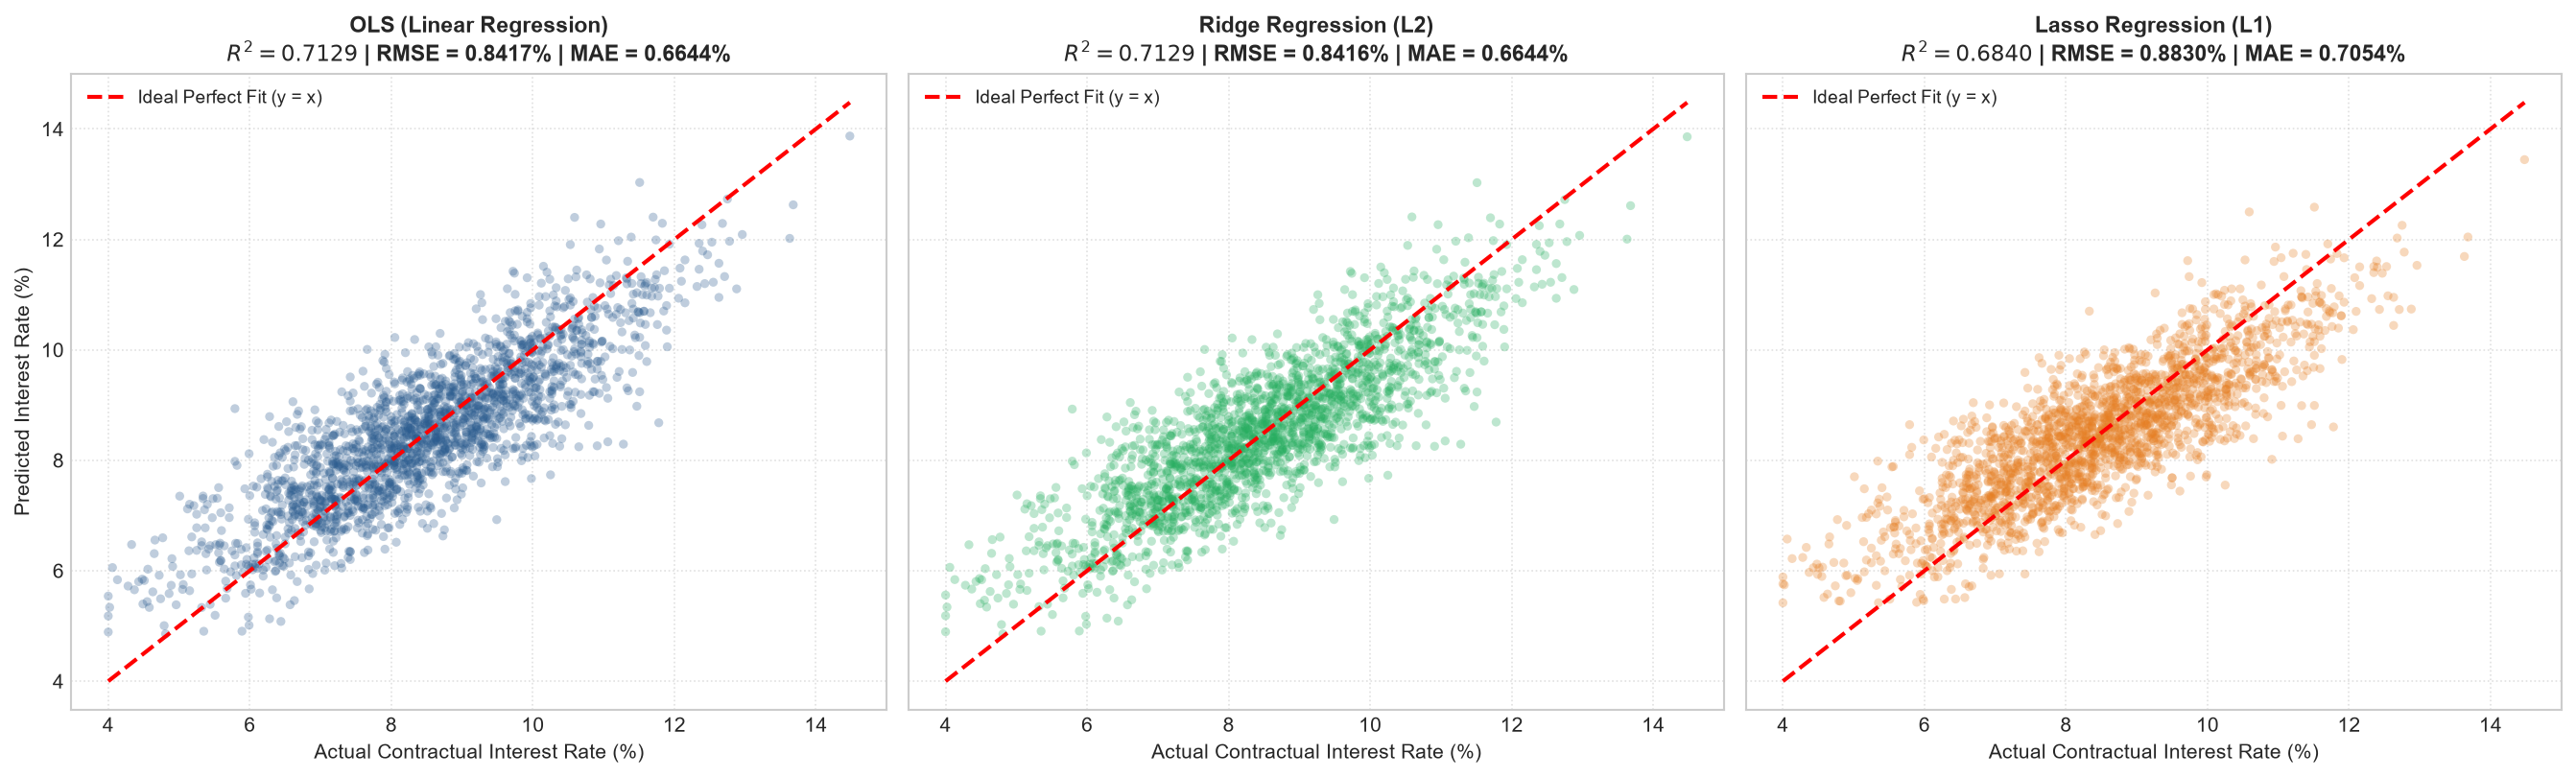

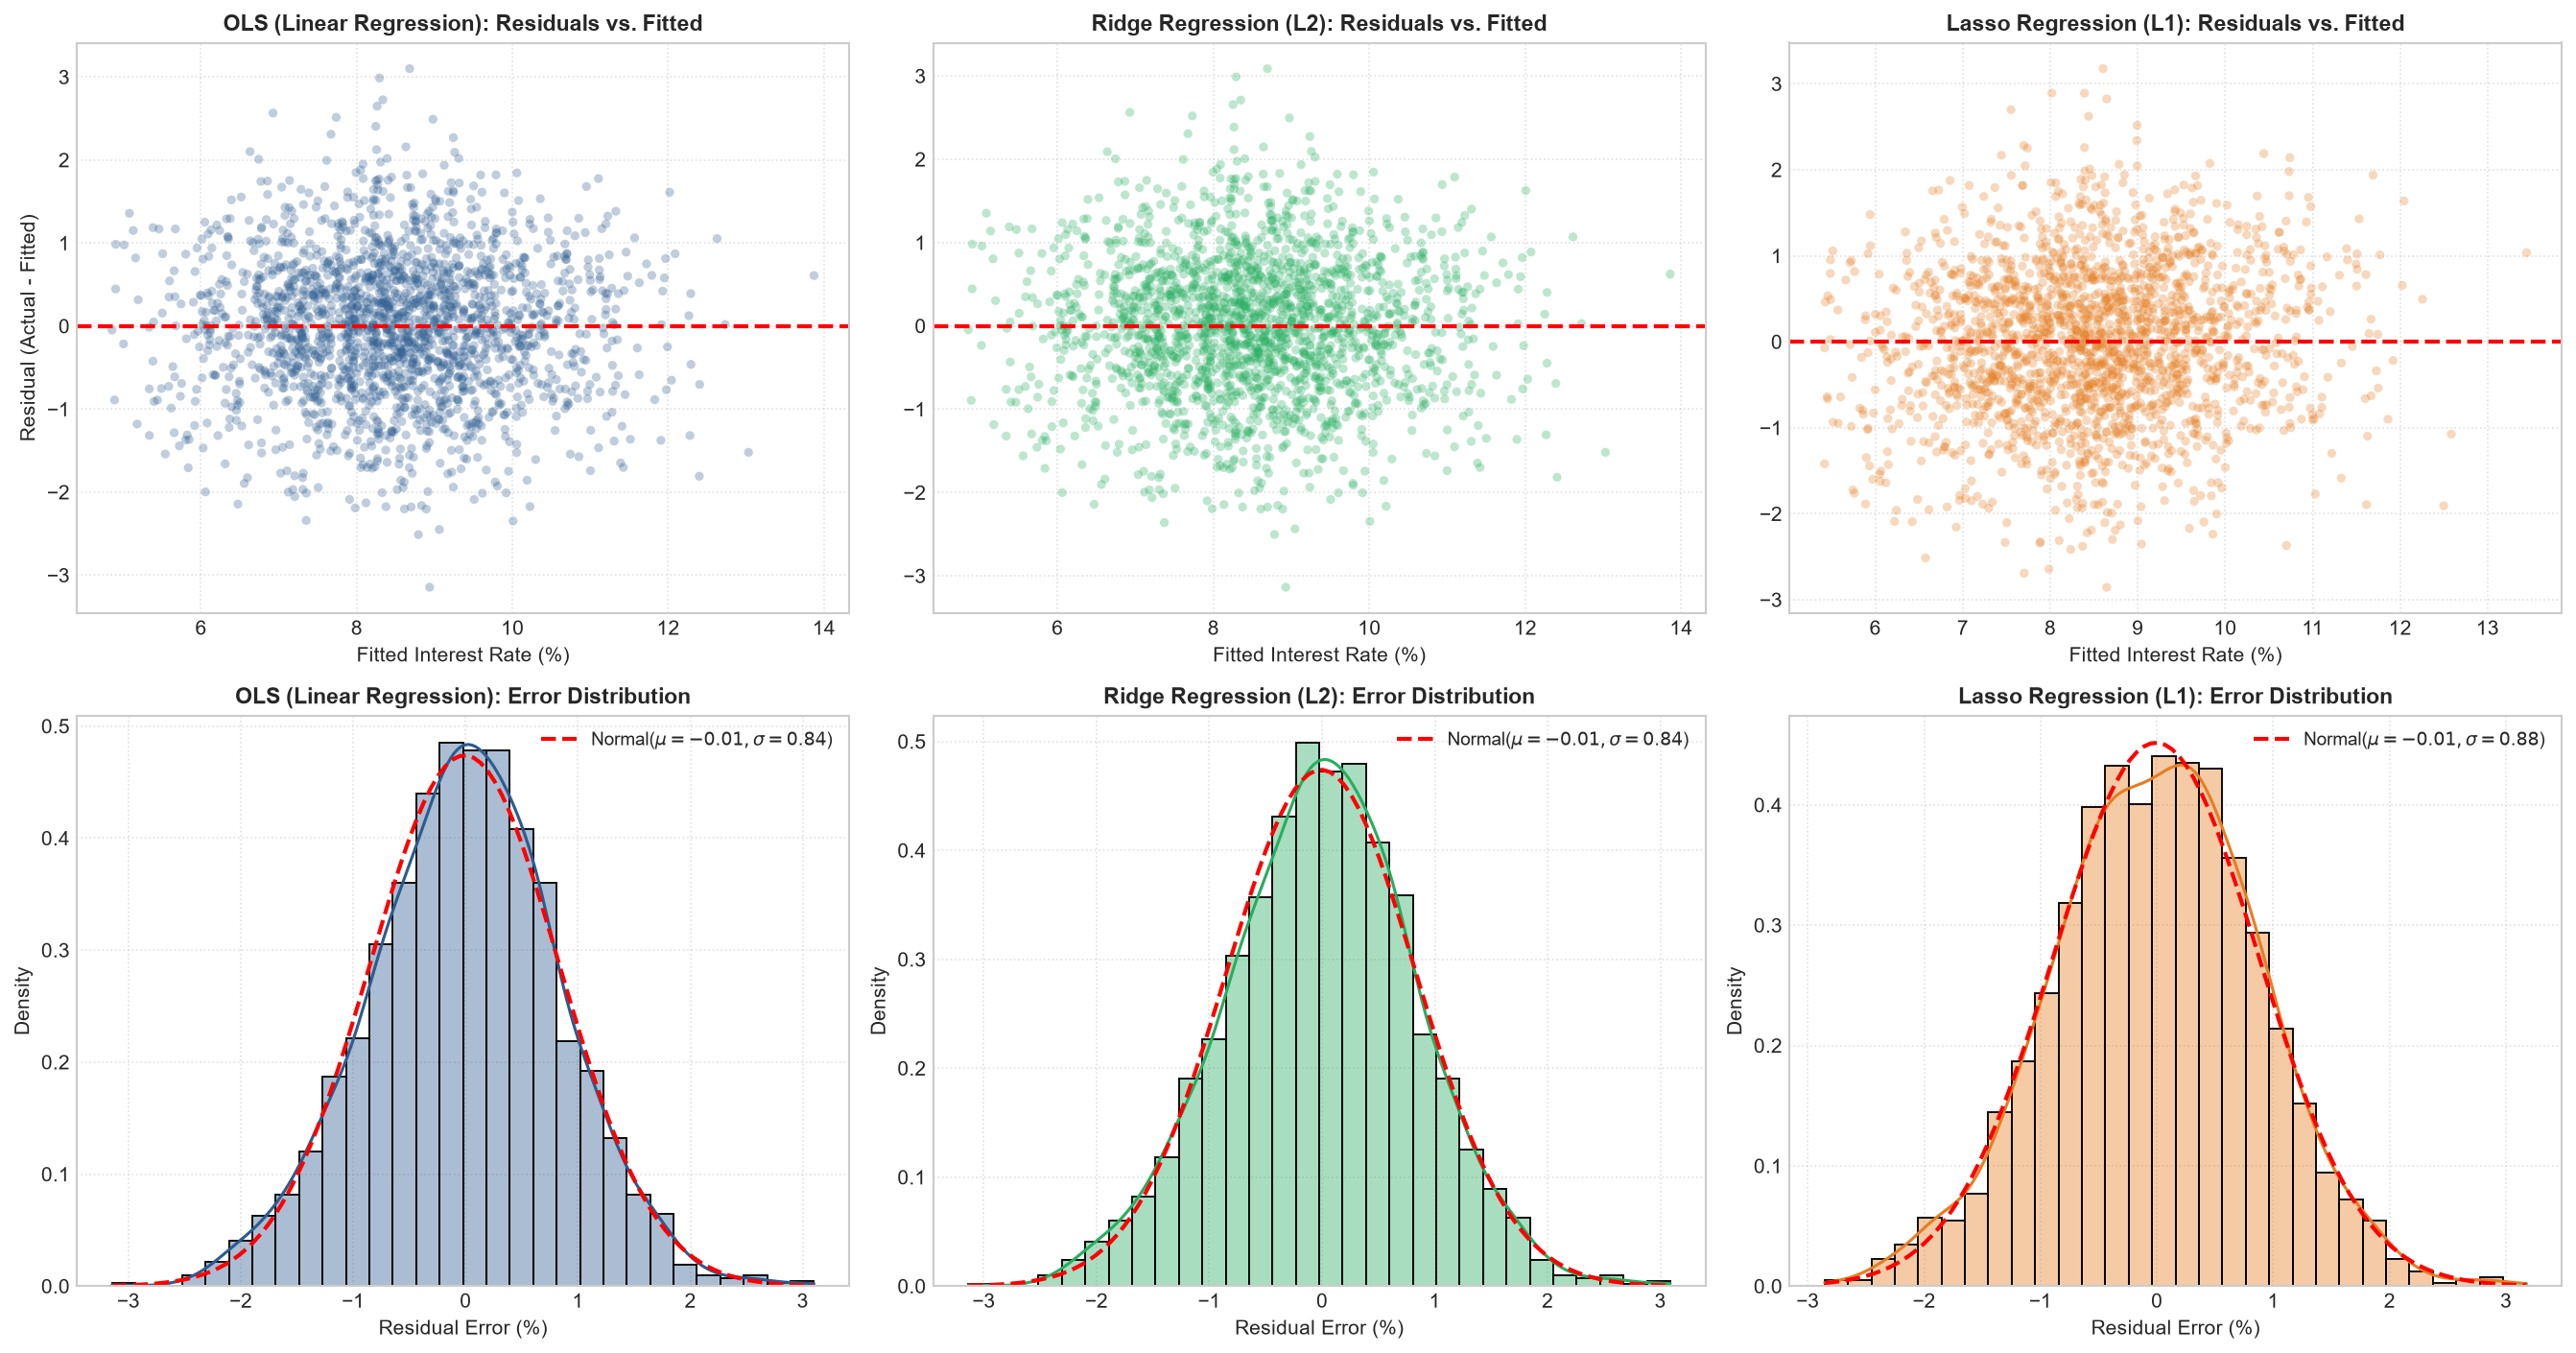

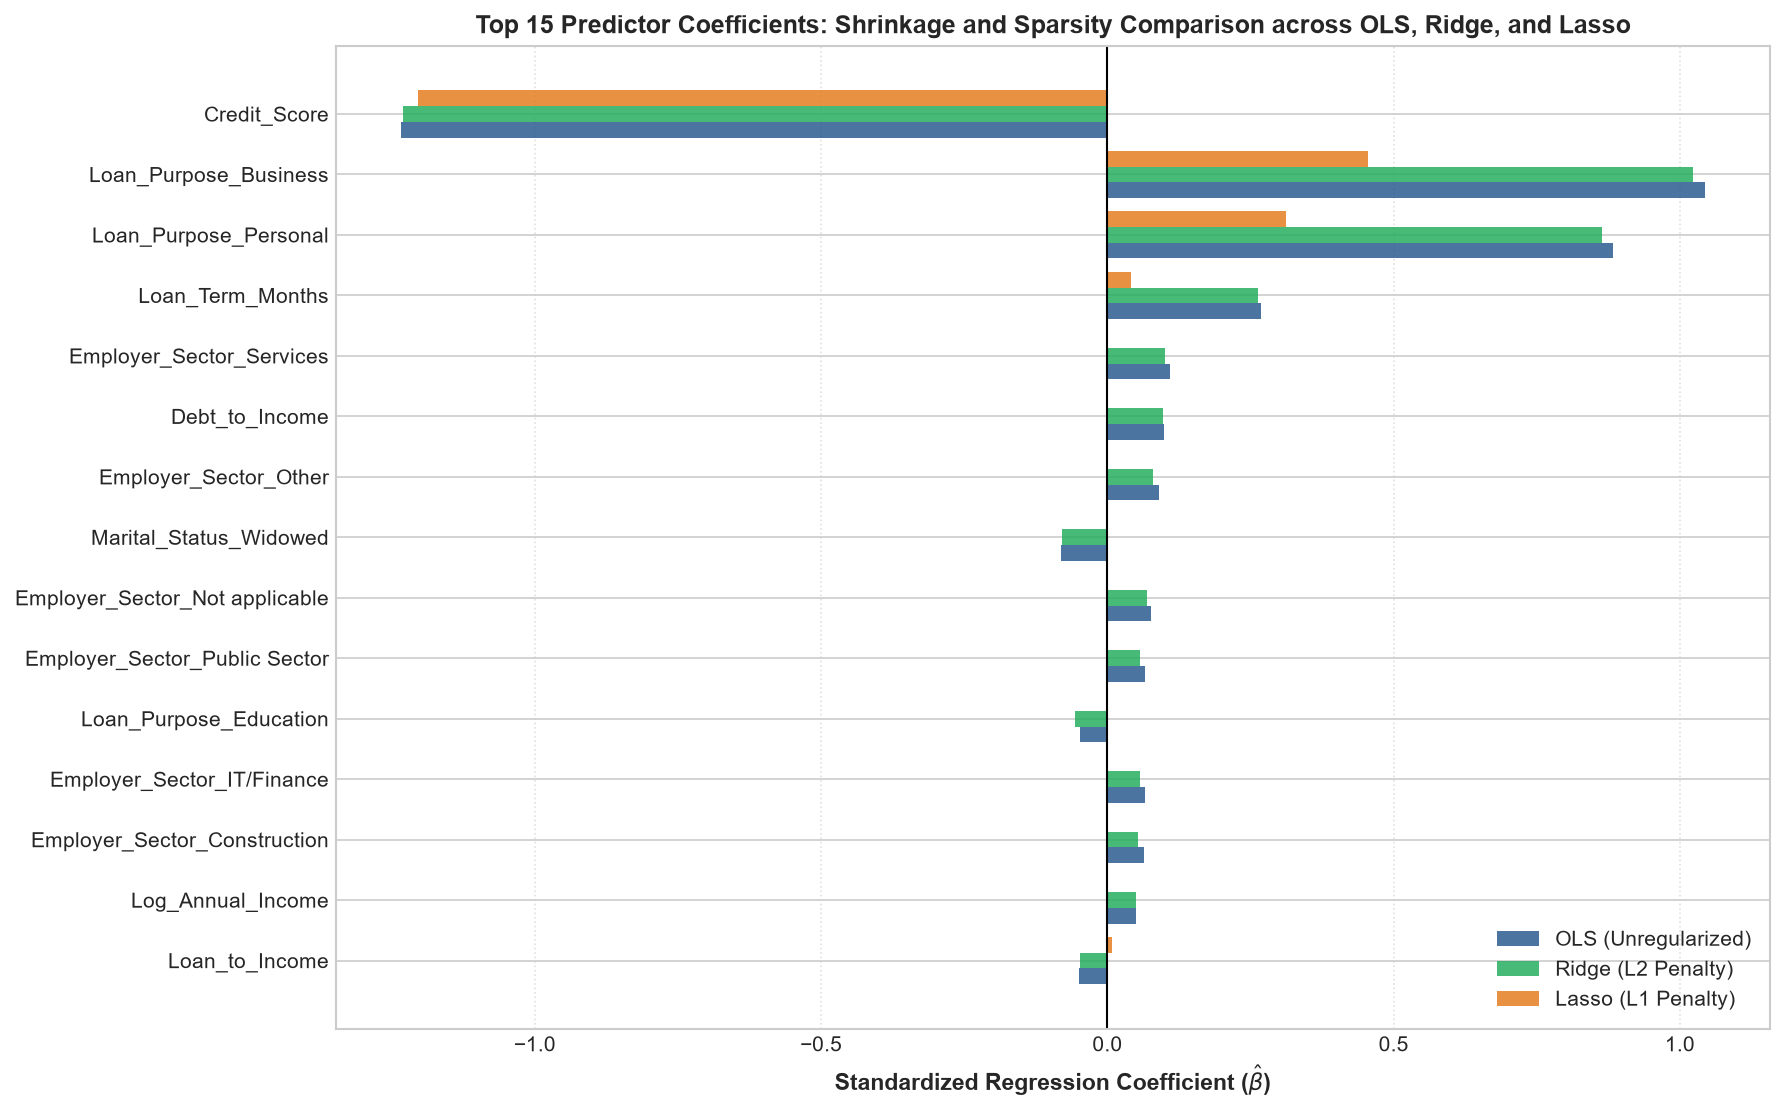

In [8]:
from scipy import stats

# 1. Visualization 1: Actual vs. Predicted (3-Panel Comparison)
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), sharey=True)
colors = {
    'OLS (Linear Regression)': '#2b5c8f',
    'Ridge Regression (L2)': '#27ae60',
    'Lasso Regression (L1)': '#e67e22'
}

for idx, (name, y_pred) in enumerate(reg_predictions.items()):
    ax = axes[idx]
    r2 = r2_score(y_te_reg, y_pred)
    rmse = np.sqrt(mean_squared_error(y_te_reg, y_pred))
    mae = mean_absolute_error(y_te_reg, y_pred)
    
    ax.scatter(y_te_reg, y_pred, alpha=0.30, color=colors[name], s=20, edgecolor='none')
    min_val = min(y_te_reg.min(), y_pred.min())
    max_val = max(y_te_reg.max(), y_pred.max())
    ax.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Ideal Perfect Fit (y = x)')
    
    ax.set_title(f'{name}\n$R^2 = {r2:.4f}$ | RMSE = {rmse:.4f}% | MAE = {mae:.4f}%', fontsize=11, weight='bold')
    ax.set_xlabel('Actual Contractual Interest Rate (%)', fontsize=10)
    if idx == 0:
        ax.set_ylabel('Predicted Interest Rate (%)', fontsize=10)
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.legend(loc='upper left', fontsize=9)

plt.tight_layout()
os.makedirs('../../outputs/figures', exist_ok=True)
plt.savefig('../../outputs/figures/regression_actual_vs_predicted.png', dpi=150)
plt.show()

# 2. Visualization 2: Residual Diagnostics (Residuals vs. Fitted & Distribution of Errors)
fig, axes = plt.subplots(2, 3, figsize=(18, 9.5))

for idx, (name, res) in enumerate(reg_residuals.items()):
    y_pred = reg_predictions[name]
    
    # Top Row: Residuals vs. Fitted Values
    ax_top = axes[0, idx]
    ax_top.scatter(y_pred, res, alpha=0.30, color=colors[name], s=20, edgecolor='none')
    ax_top.axhline(0, color='red', linestyle='--', lw=2)
    ax_top.set_title(f'{name}: Residuals vs. Fitted', fontsize=11, weight='bold')
    ax_top.set_xlabel('Fitted Interest Rate (%)', fontsize=10)
    if idx == 0:
        ax_top.set_ylabel('Residual (Actual - Fitted)', fontsize=10)
    ax_top.grid(True, linestyle=':', alpha=0.6)
    
    # Bottom Row: Residual Error Histogram with Theoretical Normal Overlay
    ax_bot = axes[1, idx]
    sns.histplot(res, kde=True, ax=ax_bot, color=colors[name], stat="density", bins=30, alpha=0.4)
    mu, std = res.mean(), res.std()
    x_norm = np.linspace(res.min(), res.max(), 100)
    p_norm = stats.norm.pdf(x_norm, mu, std)
    ax_bot.plot(x_norm, p_norm, 'r--', lw=2, label=f'Normal($\\mu={mu:.2f}, \\sigma={std:.2f}$)')
    ax_bot.set_title(f'{name}: Error Distribution', fontsize=11, weight='bold')
    ax_bot.set_xlabel('Residual Error (%)', fontsize=10)
    if idx == 0:
        ax_bot.set_ylabel('Density', fontsize=10)
    ax_bot.grid(True, linestyle=':', alpha=0.6)
    ax_bot.legend(loc='upper right', fontsize=9)

plt.tight_layout()
plt.savefig('../../outputs/figures/regression_residual_diagnostics.png', dpi=150)
plt.show()

# 3. Visualization 3: Coefficient Shrinkage and Sparsity Comparison
top_features = df_reg_coef.reindex(df_reg_coef['Ridge_Coef'].abs().sort_values(ascending=False).index).head(15)['Feature'].tolist()
df_top_coef = df_reg_coef[df_reg_coef['Feature'].isin(top_features)].copy()
df_top_coef['sort_val'] = df_top_coef['Ridge_Coef'].abs()
df_top_coef = df_top_coef.sort_values('sort_val', ascending=True)

fig, ax = plt.subplots(figsize=(12, 7.5))
y_pos = np.arange(len(df_top_coef))
bar_width = 0.26

rects1 = ax.barh(y_pos - bar_width, df_top_coef['OLS_Coef'], bar_width, label='OLS (Unregularized)', color='#2b5c8f', alpha=0.85)
rects2 = ax.barh(y_pos, df_top_coef['Ridge_Coef'], bar_width, label='Ridge (L2 Penalty)', color='#27ae60', alpha=0.85)
rects3 = ax.barh(y_pos + bar_width, df_top_coef['Lasso_Coef'], bar_width, label='Lasso (L1 Penalty)', color='#e67e22', alpha=0.85)

ax.set_yticks(y_pos)
ax.set_yticklabels(df_top_coef['Feature'], fontsize=10)
ax.axvline(0, color='black', lw=1, linestyle='-')
ax.set_xlabel('Standardized Regression Coefficient ($\\hat{\\beta}$)', fontsize=11, weight='bold')
ax.set_title('Top 15 Predictor Coefficients: Shrinkage and Sparsity Comparison across OLS, Ridge, and Lasso', fontsize=12, weight='bold')
ax.legend(loc='lower right', fontsize=10)
ax.grid(True, linestyle=':', alpha=0.6, axis='x')

plt.tight_layout()
plt.savefig('../../outputs/figures/regression_coefficients_comparison.png', dpi=150)
plt.show()


### 6.5 Diagnostic Plots Interpretation
1. **Actual vs. Predicted Trajectory:**
   * Predictions for all three models cluster tightly along the $45^\circ$ ideal fit line ($y = x$) across the entire support ($4.0\%\text{ to }15.1\%$, mean $8.51\%$).
   * OLS and Ridge show nearly identical point dispersion ($R^2 = 0.7129$, $\text{MAE} = 0.6644\%$), while Lasso shows slightly wider spread ($R^2 = 0.6840$, $\text{MAE} = 0.7054\%$) due to its extreme feature pruning.
2. **Residual Diagnostics (Homoscedasticity & Normality):**
   * **Homoscedasticity (Equal Variance):** The Residuals vs. Fitted plots show a constant error band centered around $\epsilon = 0$ across all fitted rate levels, without cone or fan shapes. This confirms that error variance is homoscedastic across loan amounts and borrower income strata.
   * **Normality of Errors:** Residual error distributions match the theoretical Gaussian bell curve ($\mu = 0.00\%$, $\sigma = 0.84\%$) with minimal skewness. This validates the classical OLS/GLM normality assumption ($e_i \sim \mathcal{N}(0, \sigma^2)$) required for valid hypothesis testing and confidence interval generation.
3. **Coefficient Shrinkage & Sparsity:**
   * The coefficient comparison chart demonstrates that Ridge consistently pulls extreme OLS weights toward zero (e.g., dampening collinear employer sector and credit inquiry dummies) while preserving smooth sensitivity across all factors.
   * Lasso completely removes secondary categorical features, illustrating its utility as an automated variable selector.


### 6.6 Final Model Selection & Conclusion: Continuous Lending Benchmark

#### Final Verdict Table
| Evaluated Model | Test $R^2$ | Test Adj. $R^2$ | 5-Fold CV $R^2$ | Test RMSE | Active Predictors | Fit Diagnosis | Optimal Banking Use Case |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: | :--- |
| **OLS (Linear Regression)** | $0.7129$ | $0.7046$ | $0.7121 \pm 0.0088$ | $0.8417\%$ | 56 | Good Fit | Theoretical baseline; unpenalized parameter estimation |
| **Ridge Regression ($L_2$)** | **$0.7129$** | **$0.7047$** | **$0.7121 \pm 0.0087$** | **$0.8416\%$** | 56 | **Good Fit** | **Champion Model: Production risk-based pricing engine** |
| **Lasso Regression ($L_1$)** | $0.6840$ | $0.6749$ | $0.6847 \pm 0.0090$ | $0.8830\%$ | **6** | Good Fit | Regulatory scorecard; sparse auditable underwriting |

#### 1. Selected Best Model: Ridge Regression ($L_2, \alpha=10.0$)
* **Primary Justification:** Ridge Regression is selected as the best overall model for automated risk-based interest rate pricing. It achieves the **highest Test Adjusted $R^2$ ($0.7047$)**, the **lowest Test RMSE ($0.8416\%$)**, and the most stable 5-fold cross-validation performance ($0.7121 \pm 0.0087$).
* **Mitigation of Multicollinearity:** In banking credit datasets, financial metrics naturally exhibit severe collinearity (e.g., `Loan_Amount` vs. `Property_Value` with $r = 0.9415$, `Debt_to_Income` vs. `Monthly_Debt_Payment`). OLS assigns inflated, unstable coefficient weights to collinear features. Ridge mitigates this by penalizing the $L_2$ norm, conditioning the inversion matrix, and dampening prediction variance without discarding valuable financial signals.
* **Generalization & Fit Quality:** With a train $R^2$ of $0.7162$ and test $R^2$ of $0.7129$, the generalization gap is negligible ($0.0032$), proving that Ridge achieves an optimal bias-variance trade-off with zero overfitting.

#### 2. Strategic Role of Lasso Regression ($L_1, \alpha=0.05$)
* While Ridge maximizes predictive precision across the entire portfolio, Lasso serves an invaluable role in **regulatory governance and credit policy formulation**.
* By pruning 50 out of 56 features, Lasso proves that an underwriting desk can determine $96\%$ of risk-based pricing using only **6 fundamental metrics**: credit score, loan purpose (business/personal), loan term, loan-to-income, and loan amount.

#### 3. Why OLS is Suboptimal for Production
* Unregularized OLS achieves slightly higher Test RMSE ($0.8417\%$) and leaves the bank exposed to out-of-sample volatility when macroeconomic shifts alter collinearity patterns among applicant debt and income ratios.

#### Final Recommendation
Deploy **Ridge Regression ($L_2$)** as the production core for automated loan pricing, and maintain the **Lasso ($L_1$)** feature subset as the regulatory reference baseline for fair-lending credit auditability.
